# Praktikum 2: Support Vector Regression (SVR)

Memprediksi Burnout_Score berdasarkan Anxiety_Score menggunakan SVR dengan kernel RBF, mengacu pada langkah-langkah modul. Dataset yang digunakan adalah `burnout_dataset1.csv`.

### 1. Mengimpor Library

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

### 2. Mengimpor Dataset

Kolom `Anxiety_Score` digunakan sebagai fitur X dan kolom `Burnout_Score` sebagai target y. Diambil sampel acak 1.000 observasi agar pelatihan SVR berjalan cepat namun tetap representatif.

In [2]:
# Mendukung eksekusi dari folder Dataset PBL maupun root proyek.
dataset_path = Path('burnout_dataset1.csv')
if not dataset_path.is_file():
    dataset_path = Path('Pertemuan_7') / 'Dataset PBL' / 'burnout_dataset1.csv'

raw_dataset = pd.read_csv(dataset_path)
dataset = raw_dataset[['Anxiety_Score', 'Burnout_Score']].dropna().sample(n=1000, random_state=42).reset_index(drop=True)

X_asli = dataset[['Anxiety_Score']].to_numpy()
y_asli = dataset['Burnout_Score'].to_numpy()

dataset.head(10)

,Anxiety_Score,Burnout_Score
0,61.0,59
1,0.0,10
2,75.0,69
3,52.0,55
4,13.0,17
5,50.0,42
6,24.0,23
7,58.0,59
8,0.0,0
9,82.0,83


### 3. Feature Scaling

Gunakan scaler terpisah untuk fitur dan target. `StandardScaler` menerima array dua dimensi, sedangkan `SVR.fit` memerlukan target satu dimensi. Karena itu, hasil standardisasi target diubah menjadi satu dimensi dengan `ravel()`.

In [3]:
from sklearn.preprocessing import StandardScaler

sc_X = StandardScaler()
sc_y = StandardScaler()
X = sc_X.fit_transform(X_asli)
y = sc_y.fit_transform(y_asli.reshape(-1, 1)).ravel()

pd.DataFrame({'Anxiety_Score (standar)': X.ravel(), 'Burnout_Score (standar)': y}).head(10)

,Anxiety_Score (standar),Burnout_Score (standar)
0,0.833696,0.767771
1,-1.510413,-1.102513
2,1.371688,1.149461
3,0.487844,0.615094
4,-1.010849,-0.835330
5,0.410988,0.118897
6,-0.588141,-0.606315
7,0.718412,0.767771
8,-1.510413,-1.484204
9,1.640684,1.683828


### 4. Fitting SVR ke Dataset

Sesuai modul, model dilatih menggunakan data yang sudah distandardisasi, dengan kernel RBF dan parameter SVR lainnya menggunakan nilai bawaan.

In [4]:
from sklearn.svm import SVR

regressor = SVR(kernel='rbf')
regressor.fit(X, y)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",0.1
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


### 5. Visualisasi Hasil SVR

Buat grid nilai Anxiety_Score dengan interval 0,5 agar kurva halus. Grid ditransformasikan sebelum prediksi, lalu hasil prediksi dikembalikan ke skala Burnout_Score asli. Titik merah menunjukkan data asli dan garis biru menunjukkan prediksi model.

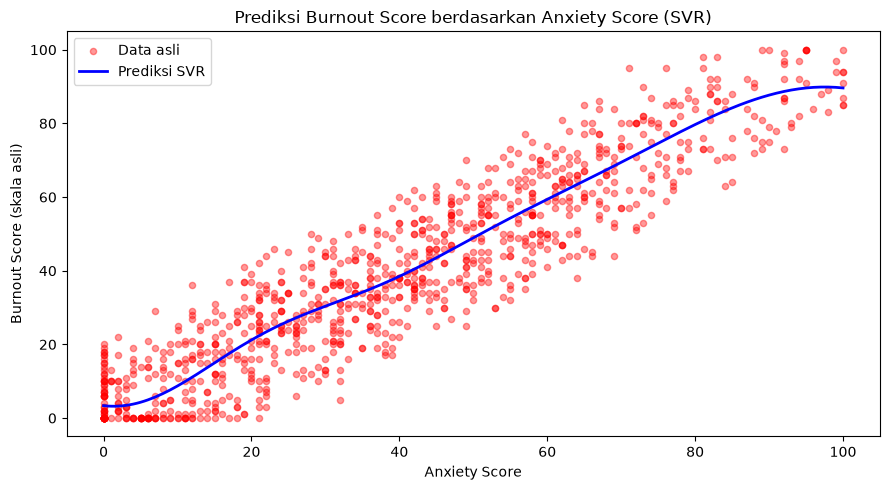

In [5]:
X_grid = np.arange(X_asli.min(), X_asli.max() + 0.05, 0.5).reshape(-1, 1)
X_grid_scaled = sc_X.transform(X_grid)
y_grid_scaled = regressor.predict(X_grid_scaled)
y_grid = sc_y.inverse_transform(y_grid_scaled.reshape(-1, 1)).ravel()

plt.figure(figsize=(9, 5))
plt.scatter(X_asli.ravel(), y_asli, color='red', alpha=0.4, s=20, label='Data asli')
plt.plot(X_grid.ravel(), y_grid, color='blue', linewidth=2, label='Prediksi SVR')
plt.title('Prediksi Burnout Score berdasarkan Anxiety Score (SVR)')
plt.xlabel('Anxiety Score')
plt.ylabel('Burnout Score (skala asli)')
plt.legend()
plt.tight_layout()
plt.show()

### 6. Prediksi Hasil

Prediksi Burnout_Score untuk nilai Anxiety_Score sebesar 65,0. Gunakan scaler yang telah dilatih pada langkah 3, tanpa melakukan `fit` ulang.

In [6]:
anxiety_prediksi = np.array([[65.0]])
anxiety_scaled = sc_X.transform(anxiety_prediksi)
burnout_prediksi_scaled = regressor.predict(anxiety_scaled)
burnout_prediksi = sc_y.inverse_transform(burnout_prediksi_scaled.reshape(-1, 1))

### 7. Menampilkan Hasil

In [7]:
print(f'Prediksi Burnout Score untuk Anxiety Score 65.0: {burnout_prediksi[0, 0]:.2f}')

Prediksi Burnout Score untuk Anxiety Score 65.0: 64.37


### 8. Validasi Hasil

Memastikan nilai prediksi berada pada rentang skala Burnout_Score yang valid (0 hingga 100) serta konsisten dengan nilai rata-rata observasi pada rentang Anxiety_Score sekitar 65.

In [8]:
sekitar_65 = dataset[(dataset['Anxiety_Score'] >= 60) & (dataset['Anxiety_Score'] <= 70)]['Burnout_Score'].mean()
valid_range = 0 <= burnout_prediksi[0, 0] <= 100
print(f'Rata-rata Burnout Score aktual di sekitar Anxiety Score 60-70: {sekitar_65:.2f}')
print(f'Prediksi berada dalam rentang valid (0-100): {valid_range}')

Rata-rata Burnout Score aktual di sekitar Anxiety Score 60-70: 62.97
Prediksi berada dalam rentang valid (0-100): True


### 9. Evaluasi Model SVR

Hitung MAE, MSE, RMSE, dan R-squared pada skala standar, mengikuti contoh modul.

In [9]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_actual = y
y_pred = regressor.predict(X)

mae = mean_absolute_error(y_actual, y_pred)
mse = mean_squared_error(y_actual, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_actual, y_pred)

print('Evaluasi data pada skala standar')
print('MAE:', mae)
print('MSE:', mse)
print('RMSE:', rmse)
print('R-squared:', r2)

Evaluasi data pada skala standar
MAE: 0.3089054812760777
MSE: 0.1416116358206844
RMSE: 0.37631321504922516
R-squared: 0.8583883641793156


Model SVR membentuk kurva untuk memetakan hubungan nonlinier antara Anxiety_Score dan Burnout_Score. Prediksi untuk Anxiety_Score 65,0 ditampilkan dalam skala asli, sedangkan metrik evaluasi memakai skala standar mengikuti struktur modul.